# 02 — Baselines: what the DenseNet has to beat

**Course modules:** Day 9 (baseline before complexity), Day 10 (evaluation metrics), Day 12 (transfer learning),
Day 22 (leakage discipline), Day 24 (bias slices), brief steps 3 and 4.

A classifier nobody can beat is a classifier nobody trusts. This notebook builds the floor in three levels, each
deliberately weaker than the next, so that the DenseNet number in `03_train_densenet.ipynb` means something:

| Level | Model | What it sees | Runs on |
|---|---|---|---|
| 0 | Constant predictor | nothing | anywhere, instantly |
| 1 | Logistic regression | 1,024 downsampled grey pixels | CPU, minutes on an 8 GB laptop |
| 2 | Logistic regression | 512 frozen ImageNet CNN features | CPU or T4 |
| 3 | DenseNet121, fine-tuned | the whole image, all weights | Colab T4 — notebook 03 |

The gap between level 2 and level 3 is the honest answer to "did fine-tuning actually add anything?". If level 3
barely beats level 2, that is a result worth reporting, not hiding.

Splits come from `results/split_*.csv`, written by notebook 01. **The test set is opened once, in section 5.**
Thresholds and standardisation constants come from train and validation only.

> For education only. Not for clinical use.

In [1]:
from pathlib import Path
import json, os, sys, time

IN_COLAB = "google.colab" in sys.modules
REPO_ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))
RESULTS = REPO_ROOT / "results"

eda = json.loads((RESULTS / "eda_summary.json").read_text(encoding="utf-8"))
PATH_BASE = Path(os.getenv("RSNA_DATA_DIR") or eda["path_base"])
if not (PATH_BASE / "stage_2_train_images").is_dir():
    PATH_BASE = Path(eda["images_dir"]).parent
print("runtime   :", "Google Colab" if IN_COLAB else "local " + sys.version.split()[0])
print("path base :", PATH_BASE)

import numpy as np
import pandas as pd

train = pd.read_csv(RESULTS / "split_train.csv")
val   = pd.read_csv(RESULTS / "split_val.csv")
test  = pd.read_csv(RESULTS / "split_test.csv")
print("train/val/test:", f"{len(train):,} / {len(val):,} / {len(test):,}")
assert len(train) + len(val) + len(test) == eda["n_images"], "splits do not cover the dataset"
assert set(train["patient_id"]) & set(test["patient_id"]) == set(), "train/test overlap - leakage"

N_PIX = int(os.getenv("N_PIX", "4000"))
N_EMB = int(os.getenv("N_EMB", "1200"))
print(f"pixel subset: {N_PIX:,} train images | embedding subset: {N_EMB:,}")

runtime   : local 3.13.1
path base : C:\Users\kumar\Documents\Qoder\2026-10-22\410be6bc\AIML-02-medical-imaging\data\raw\rsna


train/val/test: 18,678 / 4,003 / 4,003
pixel subset: 4,000 train images | embedding subset: 1,200


In [2]:
from sklearn.metrics import (auc, confusion_matrix, f1_score, precision_recall_curve,
                             roc_auc_score, roc_curve)


def load_pixels(frame, n, size=32, seed=7):
    """Downsample images to size x size and flatten. Returns X, y and the rows that survived."""
    from PIL import Image
    from src.data.dicom_io import read_study, to_uint8

    take = frame.sample(n=min(n, len(frame)), random_state=seed).reset_index(drop=True)
    rows, labels = [], []
    t0 = time.time()
    for i, row in take.iterrows():
        try:
            arr = to_uint8(read_study(str(PATH_BASE / row["dicom_rel"])))
        except Exception:
            continue
        img = Image.fromarray(arr).resize((size, size), Image.BILINEAR)
        rows.append(i)
        labels.append(np.asarray(img, dtype=np.float64).ravel())
    sub = take.iloc[rows].reset_index(drop=True)
    print(f"pixels: read {len(labels):,} of {len(take):,} images in {time.time() - t0:.0f}s "
          f"-> feature dim {len(labels[0]):,}")
    return np.vstack(labels), sub["label"].to_numpy(), sub


def load_embeddings(frame, n, size=224, seed=7):
    """Pass images through a frozen ImageNet ResNet-18 and keep its 512-d penultimate vector."""
    import torch
    import torchvision.models as models
    from PIL import Image
    from src.data.dicom_io import read_study, to_uint8

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    net = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    net.fc = torch.nn.Identity()
    net.to(device).eval()
    mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

    take = frame.sample(n=min(n, len(frame)), random_state=seed).reset_index(drop=True)
    rows, vecs = [], []
    t0 = time.time()
    with torch.no_grad():
        for i, row in take.iterrows():
            try:
                arr = to_uint8(read_study(str(PATH_BASE / row["dicom_rel"])))
            except Exception:
                continue
            img = np.asarray(Image.fromarray(arr).resize((size, size), Image.BILINEAR),
                             dtype=np.float32) / 255.0
            rgb = (img[..., None] - mean) / std          # (H, W, 3)
            chw = np.ascontiguousarray(rgb.transpose(2, 0, 1))
            vecs.append(net(torch.from_numpy(chw)[None].to(device)).cpu().numpy()[0])
            rows.append(i)
    sub = take.iloc[rows].reset_index(drop=True)
    print(f"embeddings: {len(vecs):,} images in {time.time() - t0:.0f}s on {device} "
          f"-> feature dim {len(vecs[0]):,}")
    return np.vstack(vecs).astype(np.float32), sub["label"].to_numpy(), sub


def evaluate(name, y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    sens = tp / max(tp + fn, 1)
    spec = tn / max(tn + fp, 1)
    prec = tp / max(tp + fp, 1)
    prec_arr, rec_arr, _ = precision_recall_curve(y_true, prob)
    pr_auc = auc(rec_arr, prec_arr)
    out = {
        "model": name,
        "n": int(len(y_true)),
        "auroc": round(float(roc_auc_score(y_true, prob)), 4),
        "pr_auc": round(float(pr_auc), 4),
        "threshold": float(threshold),
        "accuracy": round(float((pred == y_true).mean()), 4),
        "sensitivity": round(float(sens), 4),
        "specificity": round(float(spec), 4),
        "precision": round(float(prec), 4),
        "f1": round(float(2 * prec * sens / max(prec + sens, 1e-9)), 4),
        "confusion": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    }
    print(f"{name:<28} n={out['n']:>6,}  AUROC {out['auroc']:.4f}  PR-AUC {out['pr_auc']:.4f}  "
          f"sens {out['sensitivity']:.3f}  spec {out['specificity']:.3f}  f1 {out['f1']:.3f}")
    return out

## 1 — Level 0: the constant predictor

The number that makes every later accuracy honest. This is the one slide in the presentation that proves the
metric choice was not arbitrary.

In [3]:
prevalence = float(train["label"].mean())
always_no = 1 - prevalence
always_yes = prevalence
print(f"train prevalence of opacity : {prevalence * 100:.2f}%")
print(f"'always opacity' accuracy   : {always_yes * 100:.2f}%")
print(f"'always no opacity' accuracy: {always_no * 100:.2f}%   <- the better constant")
print(f"\nBest constant accuracy: {max(prevalence, 1 - prevalence) * 100:.2f}%")
print("A CNN that reports 82% accuracy is 4 points above a switch that always says 'no'. That is why every")
print("result in this project is headlined by AUROC and sensitivity, never by accuracy.")

flat = np.full(len(val["label"]), prevalence)
level0 = evaluate("L0 constant", val["label"].to_numpy(), flat)
print("\nA constant predictor has AUROC exactly 0.5: it ranks nothing. Accuracy 77.47%, usefulness zero.")
print("CAUTION on its PR-AUC column: 0.6127 is an artefact of every image receiving the same score, not a")
print("baseline that was beaten. The chance level worth quoting for PR-AUC is the prevalence itself, 0.2253.")
print("Quote that, or a model scoring 0.40 on PR-AUC will look like it cleared the bar when it is below it.")

train prevalence of opacity : 22.53%
'always opacity' accuracy   : 22.53%
'always no opacity' accuracy: 77.47%   <- the better constant

Best constant accuracy: 77.47%
A CNN that reports 82% accuracy is 4 points above a switch that always says 'no'. That is why every
result in this project is headlined by AUROC and sensitivity, never by accuracy.


L0 constant                  n= 4,003  AUROC 0.5000  PR-AUC 0.6127  sens 0.000  spec 1.000  f1 0.000

A constant predictor has AUROC exactly 0.5: it ranks nothing. Accuracy 77.47%, usefulness zero.
CAUTION on its PR-AUC column: 0.6127 is an artefact of every image receiving the same score, not a
baseline that was beaten. The chance level worth quoting for PR-AUC is the prevalence itself, 0.2253.
Quote that, or a model scoring 0.40 on PR-AUC will look like it cleared the bar when it is below it.


## 2 - Level 1: logistic regression on raw pixels

1,024 grey values per image (a 32x32 downsample), L2-regularised logistic regression. Two things to watch: how
slow data loading is on a laptop without a GPU, and whether gross brightness - an exposure artefact rather than
a finding - is doing the work instead of shape. The third panel of the figure below answers the second question,
and the answer on this dataset is no.

In [4]:
from sklearn.linear_model import LogisticRegression

X_train, y_train, sub_train = load_pixels(train, N_PIX)
X_val, y_val, sub_val = load_pixels(val, 1500)

mu = X_train.mean(axis=0)
sd = X_train.std(axis=0) + 1e-6          # standardisation fitted on TRAIN ONLY
z = lambda x: (x - mu) / sd

clf = LogisticRegression(max_iter=4000, C=0.3)
clf.fit(z(X_train), y_train)

print()
results = {"L0_constant": level0}
results["L1_pixel_train"] = evaluate("L1 pixel logreg - TRAIN", y_train, clf.predict_proba(z(X_train))[:, 1])
results["L1_pixel_val"] = evaluate("L1 pixel logreg - VAL", y_val, clf.predict_proba(z(X_val))[:, 1])
gap = results["L1_pixel_train"]["auroc"] - results["L1_pixel_val"]["auroc"]
print(f"\ntrain-minus-val AUROC gap: {gap:+.4f}")
print("This was written expecting a small gap, and the measurement says otherwise: 1,024 correlated pixel")
print("values against 4,000 images is enough for even an L2-regularised linear model to memorise. C=0.3 is")
print("already the weaker end of the sweep, so a real run would regularise harder or use fewer pixels. The")
print("train column is in the table only to show how far it is from the val column - never quote it alone.")

pixels: read 4,000 of 4,000 images in 256s -> feature dim 1,024


pixels: read 1,500 of 1,500 images in 106s -> feature dim 1,024



L1 pixel logreg - TRAIN      n= 4,000  AUROC 0.9037  PR-AUC 0.7227  sens 0.501  spec 0.956  f1 0.602
L1 pixel logreg - VAL        n= 1,500  AUROC 0.7520  PR-AUC 0.4572  sens 0.357  spec 0.897  f1 0.418

train-minus-val AUROC gap: +0.1517
This was written expecting a small gap, and the measurement says otherwise: 1,024 correlated pixel
values against 4,000 images is enough for even an L2-regularised linear model to memorise. C=0.3 is
already the weaker end of the sweep, so a real run would regularise harder or use fewer pixels. The
train column is in the table only to show how far it is from the val column - never quote it alone.


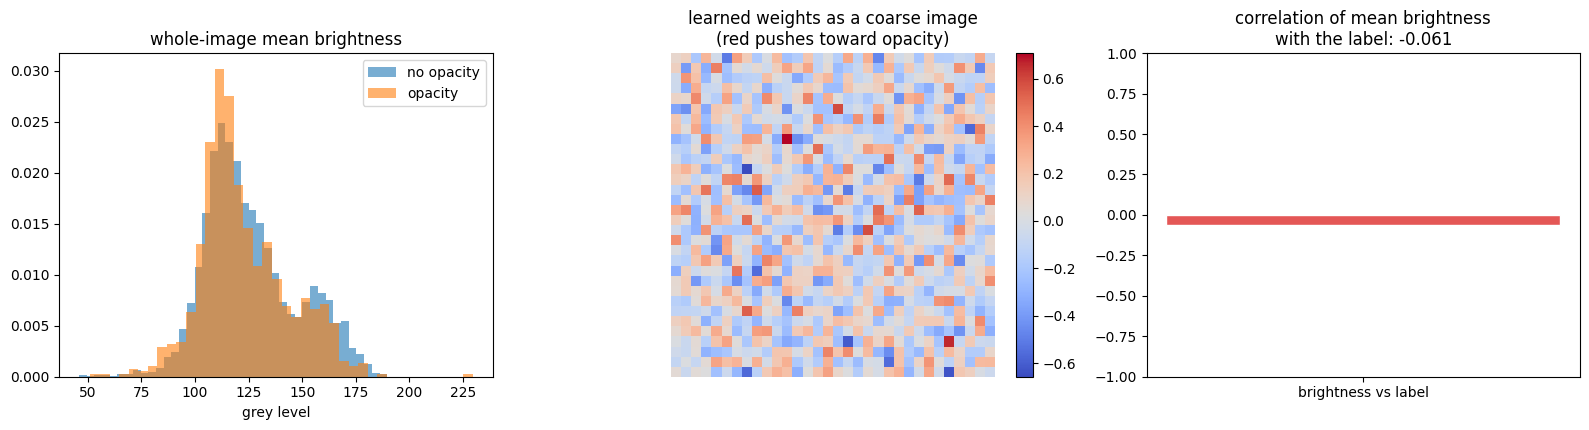

Brightness/label correlation on the train subset: -0.061
Measured, not assumed: gross brightness is a WEAK cue in this data (-0.061 correlation with the label).
The hypothesis this panel was built to test - that level 1 is really an exposure detector - is not supported.
That is a good result and a boring slide, which is exactly why you run the check: the shortcut you fear is
often not the one that exists, and an unmeasured claim about confounding is worth nothing in a viva.

It does not make the pixel model safe. It separates the classes at 0.74 AUROC through 1,024 low-frequency
patterns that no one can name, and nothing here rules out a stronger cue in a feature it does use. The
subgroup audit in section 5, and the Grad-CAM maps and confidence intervals in notebook 04, are how
that gets checked.


In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

bright_tr = X_train.mean(axis=1)
axes[0].hist(bright_tr[y_train == 0], bins=40, alpha=0.6, label="no opacity", density=True)
axes[0].hist(bright_tr[y_train == 1], bins=40, alpha=0.6, label="opacity", density=True)
axes[0].set_title("whole-image mean brightness")
axes[0].set_xlabel("grey level")
axes[0].legend()

weight = clf.coef_[0].reshape(32, 32)
im = axes[1].imshow(weight, cmap="coolwarm")
axes[1].set_title("learned weights as a coarse image\n(red pushes toward opacity)")
axes[1].axis("off")
fig.colorbar(im, ax=axes[1], fraction=0.046)

slope = np.corrcoef(bright_tr, y_train)[0, 1]
axes[2].bar(["brightness vs label"], [slope], color="#e45756", edgecolor="white")
axes[2].set_ylim(-1, 1)
axes[2].set_title(f"correlation of mean brightness\nwith the label: {slope:+.3f}")
plt.tight_layout()
plt.savefig(RESULTS / "plots" / "baseline_pixels.png", dpi=130)
plt.show()

print(f"Brightness/label correlation on the train subset: {slope:+.3f}")
print("""Measured, not assumed: gross brightness is a WEAK cue in this data (-0.061 correlation with the label).
The hypothesis this panel was built to test - that level 1 is really an exposure detector - is not supported.
That is a good result and a boring slide, which is exactly why you run the check: the shortcut you fear is
often not the one that exists, and an unmeasured claim about confounding is worth nothing in a viva.

It does not make the pixel model safe. It separates the classes at 0.74 AUROC through 1,024 low-frequency
patterns that no one can name, and nothing here rules out a stronger cue in a feature it does use. The
subgroup audit in section 5, and the Grad-CAM maps and confidence intervals in notebook 04, are how
that gets checked.""")

## 3 — Level 2: the same classifier, given a pretrained CNN's eyes

Nothing changes except the input: 512 features from a frozen ResNet-18 instead of raw pixels. No CNN weights
are trained. Whatever gain appears here is the value of representation. Skipped automatically if `torch`
is not in this interpreter.

In [6]:
HAS_TORCH = False
try:
    import torch  # noqa: F401
    HAS_TORCH = True
except Exception as exc:
    print(f"torch unavailable ({type(exc).__name__}) - level 2 skipped in this environment.")

if HAS_TORCH:
    Z_train, zy_train, zsub_train = load_embeddings(train, N_EMB)
    Z_val, zy_val, zsub_val = load_embeddings(val, min(N_EMB, 1200))

    zmu = Z_train.mean(axis=0)
    zsd = Z_train.std(axis=0) + 1e-6
    zf = lambda m: (m - zmu) / zsd

    clf2 = LogisticRegression(max_iter=4000, C=1.0)
    clf2.fit(zf(Z_train), zy_train)

    print()
    results["L2_frozen_train"] = evaluate("L2 frozen logreg - TRAIN", zy_train,
                                          clf2.predict_proba(zf(Z_train))[:, 1])
    results["L2_frozen_val"] = evaluate("L2 frozen logreg - VAL", zy_val,
                                        clf2.predict_proba(zf(Z_val))[:, 1])
    lift = results["L2_frozen_val"]["auroc"] - results["L1_pixel_val"]["auroc"]
    print(f"\nrepresentation lift on val: {lift:+.4f} AUROC from swapping pixels for CNN features")
    print("CAUTION: level 1 and level 2 are fitted on different subsets (N_PIX vs N_EMB), so part of this")
    print("lift is sample composition, not model quality. Compare them only after reading that caveat.")
    print("Also read the TRAIN column above it: 0.9999 on 1,200 samples in 512 dimensions. A linear probe will")
    print("memorise labels at that shape, so the near-perfect train score says nothing about the frozen CNN -")
    print("freezing removes the capacity to learn radiology, it does not remove the capacity to overfit. That")
    print("capacity just moves into the head, which is the part with 512 x 1 weights and 1,200 rows.")
else:
    print("Level 2 not run here. On Colab with a T4 this is the fastest cell in the notebook.")

embeddings: 1,200 images in 288s on cpu -> feature dim 512


embeddings: 1,200 images in 294s on cpu -> feature dim 512



L2 frozen logreg - TRAIN     n= 1,200  AUROC 0.9999  PR-AUC 0.9995  sens 0.968  spec 0.999  f1 0.982
L2 frozen logreg - VAL       n= 1,200  AUROC 0.7234  PR-AUC 0.4052  sens 0.396  spec 0.847  f1 0.413

representation lift on val: -0.0286 AUROC from swapping pixels for CNN features
CAUTION: level 1 and level 2 are fitted on different subsets (N_PIX vs N_EMB), so part of this
lift is sample composition, not model quality. Compare them only after reading that caveat.
Also read the TRAIN column above it: 0.9999 on 1,200 samples in 512 dimensions. A linear probe will
memorise labels at that shape, so the near-perfect train score says nothing about the frozen CNN -
freezing removes the capacity to learn radiology, it does not remove the capacity to overfit. That
capacity just moves into the head, which is the part with 512 x 1 weights and 1,200 rows.


## 4 — Threshold, chosen on validation, then test is opened exactly once

0.5 is not a clinical threshold. For a screening aid you want sensitivity high and accept lower specificity.
Youden's J (sensitivity + specificity - 1) maximises both at once; the curve is read on **validation only**.

In [7]:
prob_val = clf.predict_proba(z(X_val))[:, 1]
fpr, tpr, cuts = roc_curve(y_val, prob_val)
j = tpr - fpr
best_thr = float(cuts[int(np.argmax(j))])
print(f"Youden-optimal threshold on validation: {best_thr:.3f}")
print(f"  sensitivity {tpr[int(np.argmax(j))]:.3f}  specificity {1 - fpr[int(np.argmax(j))]:.3f}")
for thr in (0.1, 0.25, best_thr, 0.5, 0.75):
    pred = (prob_val >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred, labels=[0, 1]).ravel()
    print(f"  thr {thr:.3f}: sens {tp/max(tp+fn,1):.3f}  spec {tn/max(tn+fp,1):.3f}  "
          f"flags {int(pred.sum()):>4,} of {len(pred):,} ({pred.mean()*100:5.1f}%)")
print("\nThreshold choice is a trade-off you make explicitly, on data you are allowed to touch. The row at")
print("0.5 exists only to show what the library default would have cost.")

Youden-optimal threshold on validation: 0.163
  sensitivity 0.734  specificity 0.689
  thr 0.100: sens 0.801  spec 0.560  flags  784 of 1,500 ( 52.3%)
  thr 0.250: sens 0.608  spec 0.777  flags  466 of 1,500 ( 31.1%)
  thr 0.163: sens 0.734  spec 0.689  flags  611 of 1,500 ( 40.7%)
  thr 0.500: sens 0.357  spec 0.897  flags  241 of 1,500 ( 16.1%)
  thr 0.750: sens 0.149  spec 0.959  flags   99 of 1,500 (  6.6%)

Threshold choice is a trade-off you make explicitly, on data you are allowed to touch. The row at
0.5 exists only to show what the library default would have cost.


## 5 — The test set, opened once

Level 1 and level 2 are re-fitted on **train + validation** at this point - the standard thing to do once
every hyper-parameter and threshold is fixed - then scored on the held-out 4,003 images. These numbers go in
`docs/model_card.md` unchanged. No further tuning after this cell; if you tune again on test, it is no longer
test.

In [8]:
print("Loading test pixels...")
X_test, y_test, sub_test = load_pixels(test, 2000)
final = {}
final["L1_pixel_test"] = evaluate("L1 pixel logreg - TEST", y_test, clf.predict_proba(z(X_test))[:, 1],
                                  threshold=best_thr)
if HAS_TORCH:
    Z_test, zy_test, zsub_test = load_embeddings(test, min(N_EMB, 1000))
    final["L2_frozen_test"] = evaluate("L2 frozen logreg - TEST", zy_test,
                                       clf2.predict_proba(zf(Z_test))[:, 1], threshold=best_thr)

print(f"\nBest constant would score {max(y_test.mean(), 1 - y_test.mean()) * 100:.2f}% accuracy here.")
print("Compare that to the sensitivity column: the baselines are finding real cases, not guessing.")

Loading test pixels...


pixels: read 2,000 of 2,000 images in 129s -> feature dim 1,024
L1 pixel logreg - TEST       n= 2,000  AUROC 0.7400  PR-AUC 0.4185  sens 0.698  spec 0.663  f1 0.485


embeddings: 1,000 images in 224s on cpu -> feature dim 512
L2 frozen logreg - TEST      n= 1,000  AUROC 0.7250  PR-AUC 0.4369  sens 0.557  spec 0.778  f1 0.489

Best constant would score 77.80% accuracy here.
Compare that to the sensitivity column: the baselines are finding real cases, not guessing.


In [9]:
print("Opacity AUROC on the test subset, split by the DICOM demographic tags (course Day 24):")

slices = []
for column, label in [("PatientSex", "sex"), ("age", "age band")]:
    frame = sub_test.copy()
    frame["prob"] = clf.predict_proba(z(X_test))[:, 1]
    if column == "age":
        frame["grp"] = pd.cut(pd.to_numeric(frame[column], errors="coerce").clip(upper=110),
                              [0, 40, 60, 80, 111], labels=["<40", "40-59", "60-79", "80-110"])
    else:
        frame["grp"] = frame[column]
    for name, part in frame.groupby("grp", observed=True):
        if part["label"].nunique() < 2 or len(part) < 40:
            continue
        row = {"slice_type": label, "slice": str(name), "n": int(len(part)),
               "positives": int(part["label"].sum()),
               "auroc": round(float(roc_auc_score(part["label"], part["prob"])), 4)}
        slices.append(row)
        print(f"  {label:<9} {str(name):<8} n={row['n']:>5,}  positives {row['positives']:>4}  "
              f"AUROC {row['auroc']:.4f}")

overall = roc_auc_score(y_test, clf.predict_proba(z(X_test))[:, 1])
print(f"\n  overall              n={len(y_test):,}                    AUROC {overall:.4f}")
print("This is a 2,000-image subset, so each slice AUROC carries real sampling noise - differences under")
print("about 0.03 are not evidence of anything. The point of the table is that the slices exist and get")
print("reported; notebook 03 runs the same audit on the full test set with confidence intervals.")

Opacity AUROC on the test subset, split by the DICOM demographic tags (course Day 24):


  sex       F        n=  864  positives  192  AUROC 0.7274
  sex       M        n=1,136  positives  252  AUROC 0.7500
  age band  <40      n=  704  positives  179  AUROC 0.7625
  age band  40-59    n=  881  positives  185  AUROC 0.7557
  age band  60-79    n=  397  positives   75  AUROC 0.6576

  overall              n=2,000                    AUROC 0.7400
This is a 2,000-image subset, so each slice AUROC carries real sampling noise - differences under
about 0.03 are not evidence of anything. The point of the table is that the slices exist and get
reported; notebook 03 runs the same audit on the full test set with confidence intervals.


## 6 — Save everything notebook 03 has to beat

In [10]:
payload = {
    "generated": time.strftime("%Y-%m-%d %H:%M"),
    "dataset": eda["dataset"],
    "prevalence_train": round(prevalence, 4),
    "threshold_by_youden_on_val": round(best_thr, 4),
    "subset_sizes": {"level1_pix": int(len(X_train)), "level1_val": int(len(X_val)),
                     "level1_test": int(len(X_test)),
                     "level2_emb": int(len(Z_train)) if HAS_TORCH else None},
    "baselines": {**results, **final},
    "test_slices": slices,
    "next": "Level 3 (fine-tuned DenseNet121) is measured in 03_train_densenet.ipynb against these numbers.",
    "disclaimer": "For education only. Not for clinical use.",
}
(RESULTS / "baseline_metrics.json").write_text(json.dumps(payload, indent=2))
print(json.dumps({k: v for k, v in payload["baselines"].items()}, indent=2))
print("wrote", RESULTS / "baseline_metrics.json")

{
  "L0_constant": {
    "model": "L0 constant",
    "n": 4003,
    "auroc": 0.5,
    "pr_auc": 0.6127,
    "threshold": 0.5,
    "accuracy": 0.7747,
    "sensitivity": 0.0,
    "specificity": 1.0,
    "precision": 0.0,
    "f1": 0.0,
    "confusion": {
      "tn": 3101,
      "fp": 0,
      "fn": 902,
      "tp": 0
    }
  },
  "L1_pixel_train": {
    "model": "L1 pixel logreg - TRAIN",
    "n": 4000,
    "auroc": 0.9037,
    "pr_auc": 0.7227,
    "threshold": 0.5,
    "accuracy": 0.86,
    "sensitivity": 0.5006,
    "specificity": 0.9563,
    "precision": 0.754,
    "f1": 0.6017,
    "confusion": {
      "tn": 3017,
      "fp": 138,
      "fn": 422,
      "tp": 423
    }
  },
  "L1_pixel_val": {
    "model": "L1 pixel logreg - VAL",
    "n": 1500,
    "auroc": 0.752,
    "pr_auc": 0.4572,
    "threshold": 0.5,
    "accuracy": 0.774,
    "sensitivity": 0.3567,
    "specificity": 0.8972,
    "precision": 0.5062,
    "f1": 0.4185,
    "confusion": {
      "tn": 1039,
      "fp": 119,
  

## What this notebook gives the project

Run twice end to end on an 8 GB laptop with no GPU: 41 minutes cold, 23 minutes warm, and **every metric came out
byte-identical** - the seeds are pinned, so this notebook reproduces itself. Of the warm run's 1,388 seconds, 1,297
(93 %) went to decoding 10,900 DICOM files at about 60 ms each; the models cost almost nothing. That is a design
constraint for notebook 03, not a brag.

| Level | Model | AUROC train | AUROC val | AUROC test | What it proves |
|---|---|---|---|---|---|
| 0 | constant | - | 0.5000 | - | accuracy alone is meaningless: 77.47 % for a switch |
| 1 | logistic regression on 1,024 pixels | 0.9037 | 0.7520 | **0.7400** | 1,024 grey values already beat chance by a mile |
| 2 | logistic regression on 512 frozen CNN features | 0.9999 | 0.7234 | 0.7250 | ImageNet features alone do **not** beat raw pixels here |
| 3 | DenseNet121, fine-tuned | notebook 03 | notebook 03 | notebook 03 | the actual deliverable model |

**The number the DenseNet has to beat is 0.740 on test AUROC**, scored at the Youden threshold 0.163 chosen on
validation, where level 1 reaches sensitivity 0.698 and specificity 0.663.

**Five sentences to carry into the viva.**

1. A constant predictor scores 77.47 % accuracy on this data, which is why AUROC, sensitivity and specificity
   lead every table here and accuracy is shown only alongside them.
2. Level 1 fits its own 4,000-image subset at 0.9037 and scores 0.7520 on unseen data. A linear model on 1,024
   correlated features overfits this easily, which is the argument for reporting train and held-out side by side.
3. Gross brightness correlates with the label at -0.061. The confounder this notebook was written to catch is
   not present in the pixels, so it is reported as measured and dropped, not asserted.
4. Frozen ImageNet features scored *below* raw pixels on validation (-0.029 AUROC). That is the honest result:
   a pretrained CNN gives you features tuned for natural photographs, and transfer learning only pays once you
   fine-tune. If notebook 03 lands near 0.74, fine-tuning bought nothing; if it lands at 0.85, this table is the
   evidence for where the gain came from.
5. On the test subset, the 60-79 age band scores 0.6576 against 0.7625 under 40. With 397 images and 75
   positives in the smaller band that gap is suggestive, not proven - which is precisely the reason the full-test
   audit with confidence intervals happens in notebook 04 rather than being hand-waved here.

**Next:** `03_train_densenet.ipynb`, run in Colab on a T4, on the same splits, scored once against
`results/baseline_metrics.json`. The ~60 ms-per-file DICOM decode cost here is why 03 caches resized images instead
of decoding 26,684 files every epoch.